# Two-Stage Heart Disease Prediction: A Hybrid Architecture

In clinical machine learning, missing an actual patient (False Negative) carries a much higher cost than a false alarm. However, forcing a model to be overly sensitive inevitably pulls healthy individuals with overlapping medical profiles into the positive class.

This notebook tests a **Two-Stage Hybrid Architecture** designed to solve this exact trade-off:
* **Stage 1 (The Wide Net):** A high-sensitivity PyTorch Deep Neural Network trained with class-weighted loss and a lowered decision threshold to capture as many true patients as possible (maximizing Recall).
* **Stage 2 (The Distribution Inspector):** Every positive prediction from Stage 1 is inspected by a distance-based **One-Class SVM (OCSVM)** trained exclusively on confirmed patients.

If Stage 1 predicts **Positive**, but Stage 2 detects that the patient's spatial profile deviates from the true disease distribution, the case is isolated and flagged for **Medical Review** rather than making a blind classification.

In [1]:
# To keep the connection alive
import threading
import time

def background_keep_alive():
    while True:
        with open("colab_keep_alive.txt", "a") as f:
            f.write(f"Active at {time.ctime()}\n")
        time.sleep(180)

bg_thread = threading.Thread(target=background_keep_alive, daemon=True)
bg_thread.start()

In [2]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

In [3]:
!kaggle datasets download -d alexteboul/heart-disease-health-indicators-dataset
!unzip -q heart-disease-health-indicators-dataset.zip -d my_dataset_folder

Dataset URL: https://www.kaggle.com/datasets/alexteboul/heart-disease-health-indicators-dataset
License(s): CC0-1.0
heart-disease-health-indicators-dataset.zip: Skipping, found more recently modified local copy (use --force to force download)
replace my_dataset_folder/heart_disease_health_indicators_BRFSS2015.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: n


In [4]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats as stats

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import KNNImputer
from sklearn.decomposition import PCA
from sklearn.svm import OneClassSVM
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

## 1. Data Loading & Initial Overview

In [6]:
temp_df = pd.read_csv("/content/my_dataset_folder/heart_disease_health_indicators_BRFSS2015.csv")

X_temp = temp_df.drop('HeartDiseaseorAttack', axis=1)
y_temp = temp_df['HeartDiseaseorAttack']
X, _, y, _ = train_test_split(X_temp, y_temp, test_size=0.6, random_state=42, shuffle=True, stratify=y_temp)

df = pd.concat([X,y], axis=1)

In [7]:
print(f"Dataset Shape: {df.shape}")
df.head()

Dataset Shape: (101472, 22)


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,Diabetes,PhysActivity,Fruits,Veggies,...,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,HeartDiseaseorAttack
35840,0.0,1.0,1.0,22.0,1.0,0.0,2.0,0.0,1.0,1.0,...,0.0,4.0,30.0,5.0,1.0,0.0,4.0,4.0,2.0,0.0
244032,1.0,1.0,1.0,25.0,1.0,0.0,0.0,1.0,1.0,0.0,...,1.0,4.0,1.0,0.0,0.0,1.0,5.0,5.0,6.0,0.0
17498,1.0,1.0,1.0,31.0,0.0,0.0,1.0,0.0,0.0,1.0,...,0.0,4.0,5.0,0.0,0.0,1.0,10.0,4.0,5.0,0.0
219768,1.0,1.0,1.0,28.0,1.0,0.0,0.0,1.0,0.0,1.0,...,0.0,4.0,30.0,20.0,0.0,0.0,9.0,4.0,5.0,0.0
94230,0.0,1.0,1.0,24.0,1.0,0.0,0.0,0.0,0.0,1.0,...,0.0,2.0,20.0,0.0,0.0,0.0,9.0,6.0,7.0,0.0


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 101472 entries, 35840 to 168592
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   HighBP                101472 non-null  float64
 1   HighChol              101472 non-null  float64
 2   CholCheck             101472 non-null  float64
 3   BMI                   101472 non-null  float64
 4   Smoker                101472 non-null  float64
 5   Stroke                101472 non-null  float64
 6   Diabetes              101472 non-null  float64
 7   PhysActivity          101472 non-null  float64
 8   Fruits                101472 non-null  float64
 9   Veggies               101472 non-null  float64
 10  HvyAlcoholConsump     101472 non-null  float64
 11  AnyHealthcare         101472 non-null  float64
 12  NoDocbcCost           101472 non-null  float64
 13  GenHlth               101472 non-null  float64
 14  MentHlth              101472 non-null  float64
 15  P

In [9]:
df.isna().sum().sum()

np.int64(0)

In [10]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
HighBP,101472.0,0.428493,0.494863,0.0,0.0,0.0,1.0,1.0
HighChol,101472.0,0.424245,0.494230,0.0,0.0,0.0,1.0,1.0
CholCheck,101472.0,0.962995,0.188776,0.0,1.0,1.0,1.0,1.0
BMI,101472.0,28.382677,6.586482,12.0,24.0,27.0,31.0,98.0
Smoker,101472.0,0.443896,0.496845,0.0,0.0,0.0,1.0,1.0
Stroke,101472.0,0.040612,0.197391,0.0,0.0,0.0,0.0,1.0
Diabetes,101472.0,0.299186,0.700206,0.0,0.0,0.0,0.0,2.0
PhysActivity,101472.0,0.757874,0.428372,0.0,1.0,1.0,1.0,1.0
Fruits,101472.0,0.633219,0.481928,0.0,0.0,1.0,1.0,1.0
Veggies,101472.0,0.811958,0.390748,0.0,1.0,1.0,1.0,1.0


In [11]:
# Programmatically inspect cardinality and value ranges to deduce feature types
cardinality_df = pd.DataFrame({
    "Dtype": df.dtypes,
    "Unique_Count": df.nunique(),
    "Min_Val": df.min(),
    "Max_Val": df.max(),
    "Sample_Unique_Values": [sorted(df[c].unique())[:6] for c in df.columns]
})

cardinality_df.sort_values(by="Unique_Count")

,Dtype,Unique_Count,Min_Val,Max_Val,Sample_Unique_Values
HighBP,float64,2,0.0,1.0,"[0.0, 1.0]"
HighChol,float64,2,0.0,1.0,"[0.0, 1.0]"
CholCheck,float64,2,0.0,1.0,"[0.0, 1.0]"
Smoker,float64,2,0.0,1.0,"[0.0, 1.0]"
PhysActivity,float64,2,0.0,1.0,"[0.0, 1.0]"
Stroke,float64,2,0.0,1.0,"[0.0, 1.0]"
Veggies,float64,2,0.0,1.0,"[0.0, 1.0]"
Fruits,float64,2,0.0,1.0,"[0.0, 1.0]"
NoDocbcCost,float64,2,0.0,1.0,"[0.0, 1.0]"
AnyHealthcare,float64,2,0.0,1.0,"[0.0, 1.0]"


### Observations & Data Dictionary Alignment

While the table above provides a structural overview, referencing the official **CDC BRFSS Data Dictionary** confirms these `float64` columns represent three distinct statistical groups. To programmatically categorize them, we use thresholds aligned with the codebook's maximum ordinal scale (13 age categories):

1. **Binary Features (`Unique_Count == 2`):** Strictly `0.0` and `1.0` indicators.
2. **Ordinal / Scale Features (`2 < Unique_Count <= 15`):** Discrete ranked survey categories (e.g., scales spanning `1-5`, `1-8`, up to the maximum `1-13`).
3. **Continuous / Count Features (`Unique_Count > 15`):** Numeric measurements or 30-day continuous counts, which all naturally exceed 15 unique values in this dataset.

In [12]:
target_col = "HeartDiseaseorAttack"
feature_cols = [c for c in df.columns if c != target_col]

binary_cols = [c for c in feature_cols if df[c].nunique() == 2]
ordinal_cols = [c for c in feature_cols if 2 < df[c].nunique() <= 15]
continuous_cols = [c for c in feature_cols if df[c].nunique() > 15]

print(f"Binary Features ({len(binary_cols)}): {binary_cols}")
print(f"Ordinal Features ({len(ordinal_cols)}): {ordinal_cols}")
print(f"Continuous Features ({len(continuous_cols)}): {continuous_cols}")

Binary Features (13): ['HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'DiffWalk', 'Sex']
Ordinal Features (5): ['Diabetes', 'GenHlth', 'Age', 'Education', 'Income']
Continuous Features (3): ['BMI', 'MentHlth', 'PhysHlth']


## 2. Exploratory Data Analysis (EDA)
Now that features are grouped based on their discovered cardinality, we evaluate class imbalance, inter-feature correlations, and statistical significance against the target variable.

In [13]:
target_summary = pd.DataFrame({
    "Count": df[target_col].value_counts(),
    "Percentage (%)": (df[target_col].value_counts(normalize=True) * 100).round(2)
})
print(target_summary)

                      Count  Percentage (%)
HeartDiseaseorAttack                       
0.0                   91915           90.58
1.0                    9557            9.42


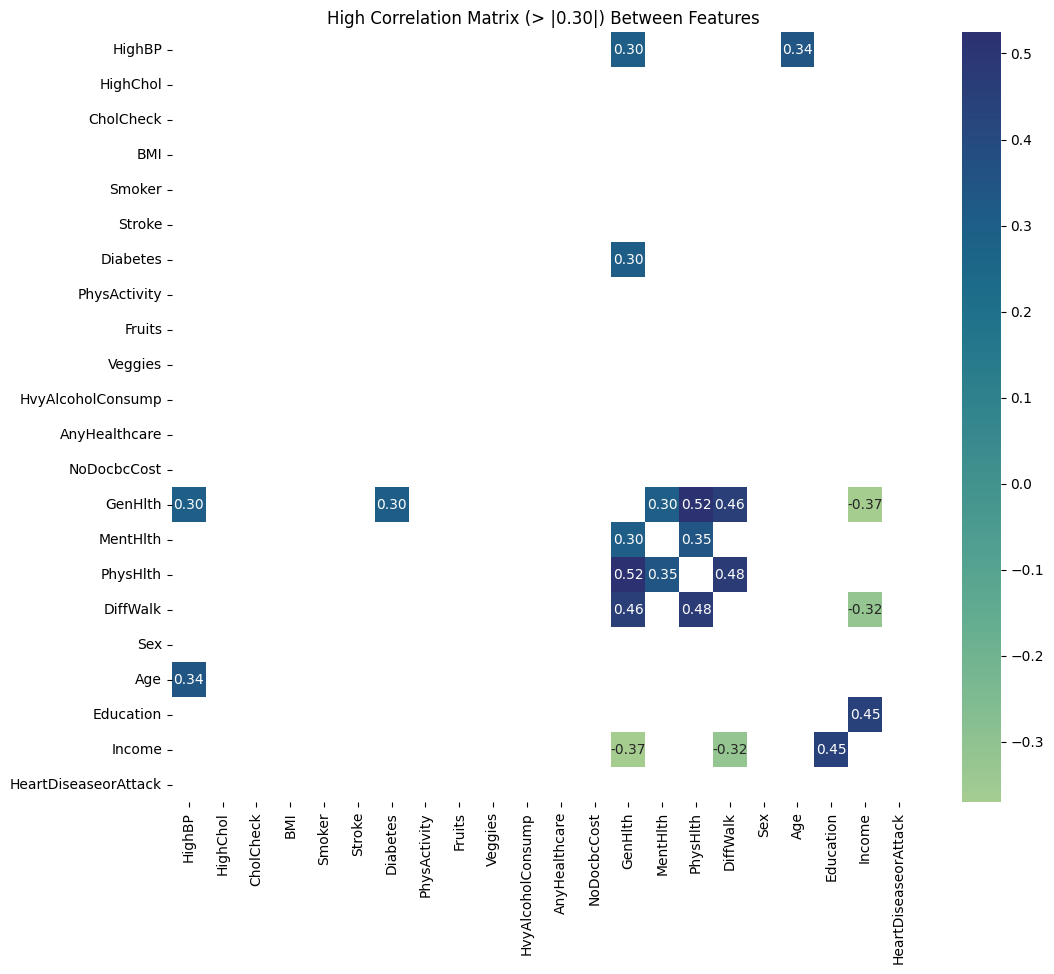

--- Linear Correlation with HeartDiseaseorAttack ---
GenHlth              0.2588
Age                  0.2216
DiffWalk             0.2103
HighBP               0.2102
Stroke               0.2058
HighChol             0.1858
PhysHlth             0.1810
Diabetes             0.1808
Smoker               0.1144
Sex                  0.0845
MentHlth             0.0634
BMI                  0.0556
CholCheck            0.0444
NoDocbcCost          0.0289
AnyHealthcare        0.0200
Fruits              -0.0178
HvyAlcoholConsump   -0.0296
Veggies             -0.0382
PhysActivity        -0.0895
Education           -0.0991
Income              -0.1382
Name: HeartDiseaseorAttack, dtype: float64


In [14]:
plt.figure(figsize=(12, 10))
corr_matrix = df.corr()

# Mask weak correlations (< |0.30|) and self-correlations (1.0)
high_corr_mask = (np.abs(corr_matrix) < 0.30) | (corr_matrix == 1.0)
filtered_corr = corr_matrix.mask(high_corr_mask)

sns.heatmap(filtered_corr, annot=True, fmt=".2f", cmap="crest", cbar=True)
plt.title("High Correlation Matrix (> |0.30|) Between Features")
plt.show()

print(f"--- Linear Correlation with {target_col} ---")
print(corr_matrix[target_col].drop(target_col).sort_values(ascending=False).round(4))

In [15]:
chi2_records = []
for col in binary_cols + ordinal_cols:
    table = pd.crosstab(df[col], df[target_col])
    chi2_stat, p_val, _, _ = stats.chi2_contingency(table)
    ftype = "Binary" if col in binary_cols else "Ordinal"
    chi2_records.append({"Feature": col, "Type": ftype, "Chi2_Stat": round(chi2_stat, 2), "p_value": p_val})

chi2_df = pd.DataFrame(chi2_records).sort_values(by="Chi2_Stat", ascending=False).reset_index(drop=True)
chi2_df

,Feature,Type,Chi2_Stat,p_value
0,GenHlth,Ordinal,7618.48,0.000000e+00
1,Age,Ordinal,5489.78,0.000000e+00
2,DiffWalk,Binary,4484.74,0.000000e+00
3,HighBP,Binary,4481.77,0.000000e+00
4,Stroke,Binary,4293.24,0.000000e+00
5,HighChol,Binary,3501.37,0.000000e+00
6,Diabetes,Ordinal,3319.98,0.000000e+00
7,Income,Ordinal,2044.74,0.000000e+00
8,Smoker,Binary,1327.34,1.294637e-290
9,Education,Ordinal,1026.29,1.218866e-219


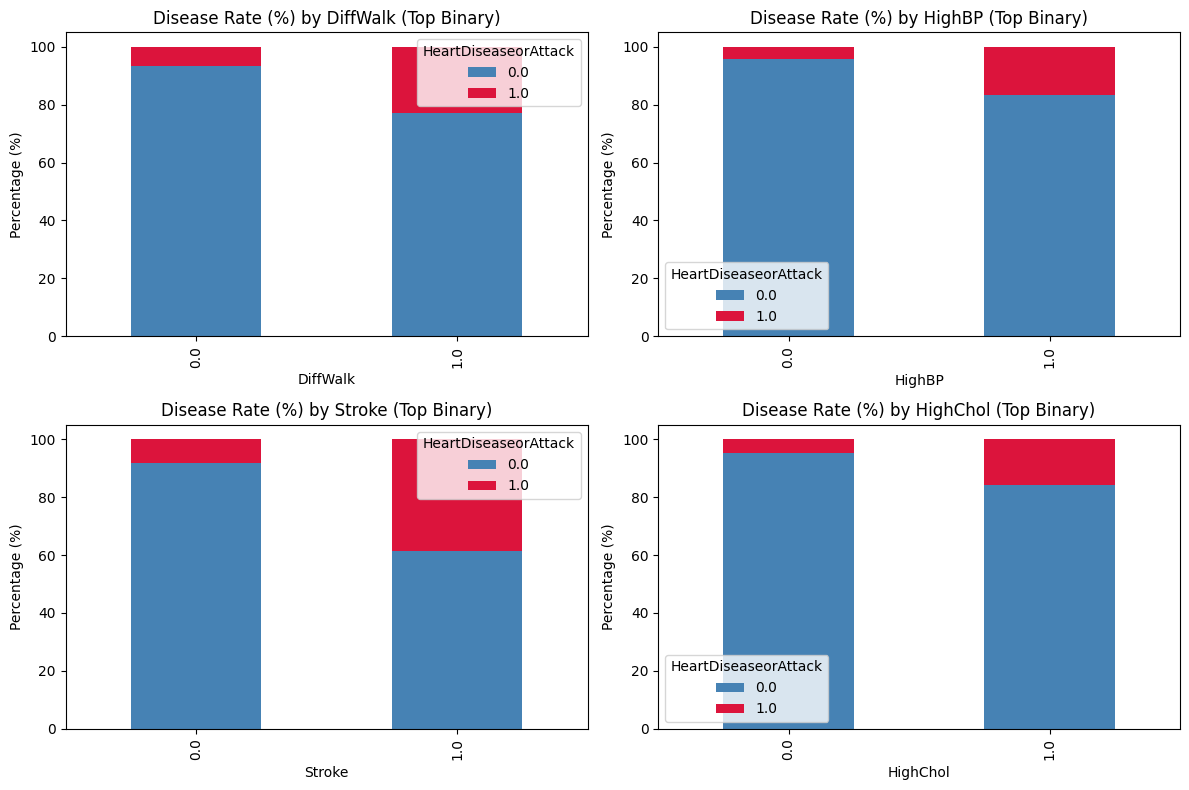

In [16]:
top_4_binary = chi2_df[chi2_df["Type"] == "Binary"]["Feature"].head(4).tolist()

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flatten(), top_4_binary):
    prop_df = df.groupby(col)[target_col].value_counts(normalize=True).unstack() * 100
    prop_df.plot(kind="bar", stacked=True, ax=ax, color=["steelblue", "crimson"])
    ax.set_title(f"Disease Rate (%) by {col} (Top Binary)")
    ax.set_ylabel("Percentage (%)")

plt.tight_layout()
plt.show()

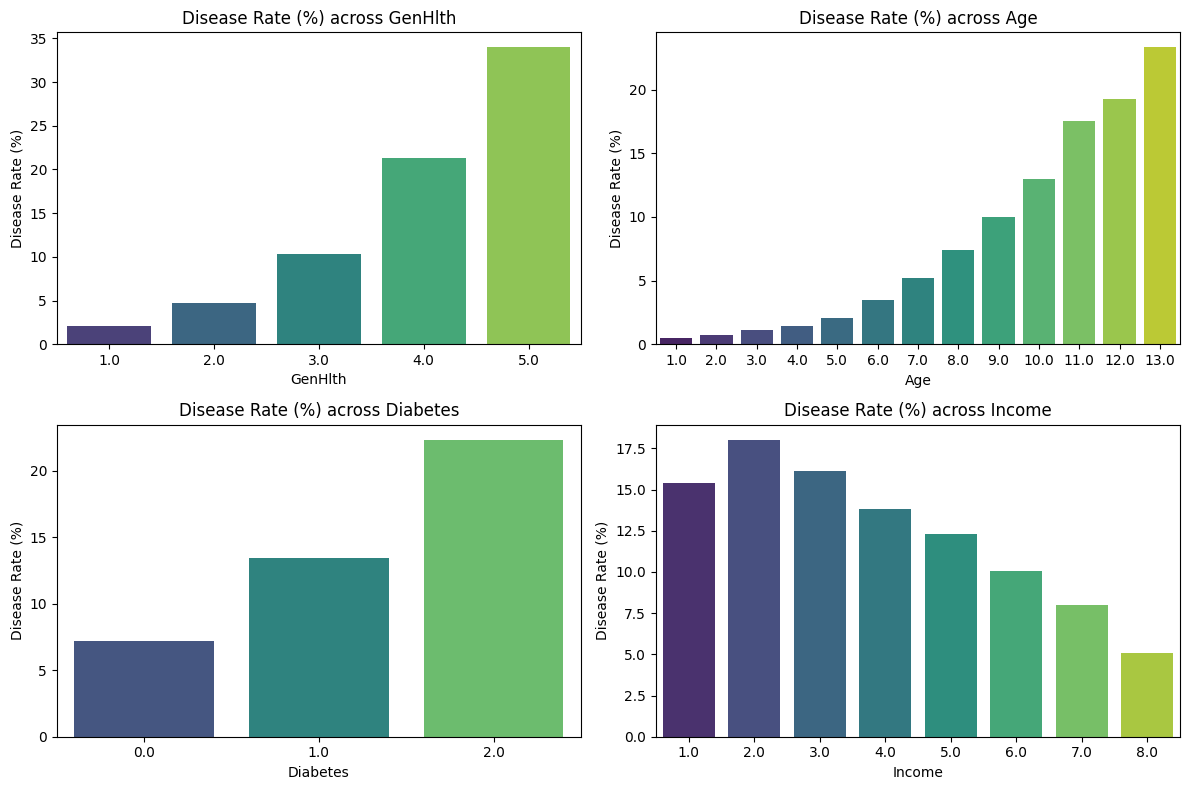

In [17]:
top_4_ordinal = chi2_df[chi2_df["Type"] == "Ordinal"]["Feature"].head(4).tolist()

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flatten(), top_4_ordinal):
    risk_rate = df.groupby(col)[target_col].mean() * 100
    sns.barplot(x=risk_rate.index, y=risk_rate.values, ax=ax, palette="viridis")
    ax.set_title(f"Disease Rate (%) across {col}")
    ax.set_ylabel("Disease Rate (%)")

plt.tight_layout()
plt.show()

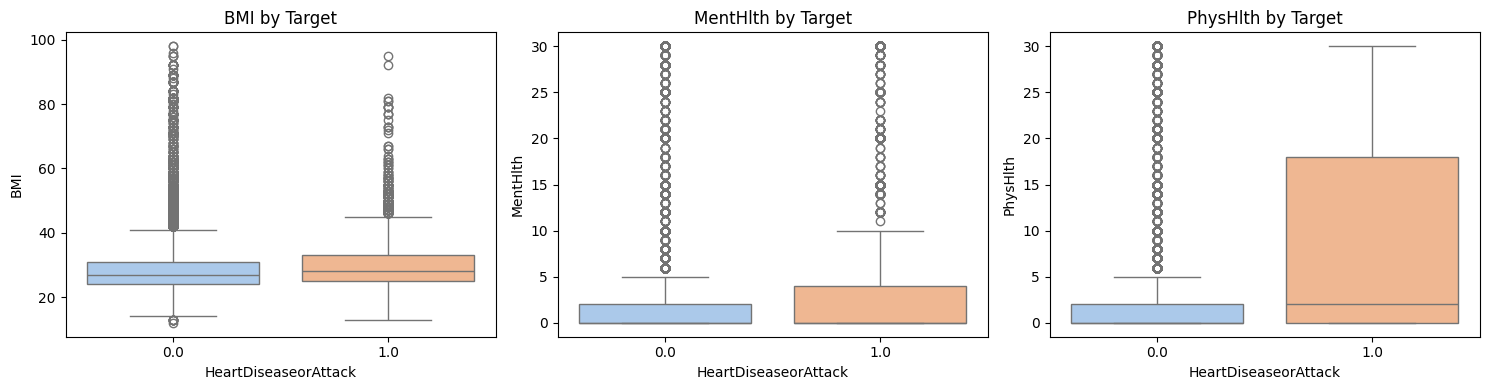

Skewness of Continuous Features:
BMI         2.10
MentHlth    2.72
PhysHlth    2.21
dtype: float64


In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, continuous_cols):
    sns.boxplot(data=df, x=target_col, y=col, palette="pastel", ax=ax)
    ax.set_title(f"{col} by Target")

plt.tight_layout()
plt.show()

print("Skewness of Continuous Features:")
print(df[continuous_cols].skew().round(2))

### Statistical Test for Continuous Features
Since the boxplots and skewness values above show heavy right-skewness (`Skewness > 1.0` for all three features) and numerous outliers, the normality assumption required for a parametric T-Test is violated. Therefore, we apply the non-parametric **Mann-Whitney U Test**.

In [19]:
mw_records = []
for col in continuous_cols:
    healthy_grp = df[df[target_col] == 0][col]
    patient_grp = df[df[target_col] == 1][col]
    u_stat, p_val = stats.mannwhitneyu(patient_grp, healthy_grp)
    mw_records.append({
        "Feature": col,
        "Healthy_Median": healthy_grp.median(),
        "Patient_Median": patient_grp.median(),
        "U_Stat": u_stat,
        "p_value": p_val
    })

pd.DataFrame(mw_records)

,Feature,Healthy_Median,Patient_Median,U_Stat,p_value
0,BMI,27.0,28.0,497691773.0,1.750956e-102
1,MentHlth,0.0,0.0,463131672.0,6.579931e-27
2,PhysHlth,0.0,2.0,556774445.0,0.000000e+00


## 3. Data Splitting & Standardization
With zero missing values confirmed during discovery, we perform a stratified 3-way split (70% Train, 15% Validation, 15% Test) to preserve the ~9.4% positive class ratio across all sets. We then standardize all features using `Train` statistics so neither large scales (`BMI`, `Age`) nor binary flags distort Neural Network gradients or OCSVM distance calculations.

In [20]:
X = df.drop(columns=[target_col])
y = df[target_col]

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp)

print(f"Train: {X_train.shape} | Val: {X_val.shape} | Test: {X_test.shape}")

Train: (71030, 21) | Val: (15221, 21) | Test: (15221, 21)


In [21]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

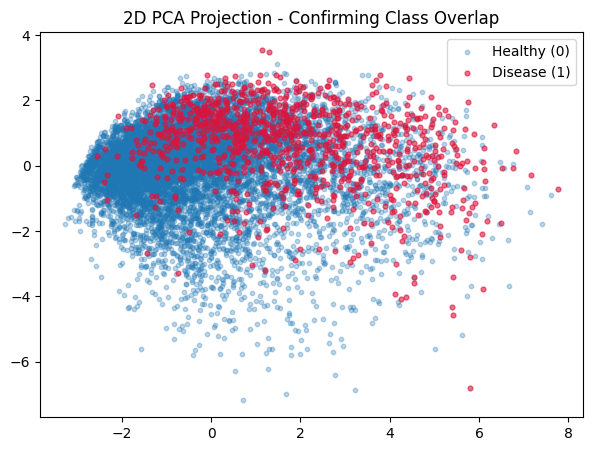

In [22]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_train_scaled[:10000])
y_sample = y_train.values[:10000]

plt.figure(figsize=(7, 5))
plt.scatter(X_pca[y_sample == 0, 0], X_pca[y_sample == 0, 1], alpha=0.3, label="Healthy (0)", s=10)
plt.scatter(X_pca[y_sample == 1, 0], X_pca[y_sample == 1, 1], alpha=0.6, label="Disease (1)", color="crimson", s=12)
plt.title("2D PCA Projection - Confirming Class Overlap")
plt.legend()
plt.show()

## 4. Stage 1: High-Sensitivity PyTorch Neural Network
The PCA projection confirms that positive cases are heavily embedded within the healthy distribution. To balance sensitivity (Recall) without triggering excessive false alarms (low Precision), we apply a moderated positive class weight (`0.50 * neg_pos_ratio`) and a lower learning rate (`5e-4`) for smoother gradient convergence.

In [23]:
torch.manual_seed(42)

X_train_t = torch.FloatTensor(X_train_scaled)
y_train_t = torch.FloatTensor(y_train.values).unsqueeze(1)
X_val_t = torch.FloatTensor(X_val_scaled)
y_val_t = torch.FloatTensor(y_val.values).unsqueeze(1)
X_test_t = torch.FloatTensor(X_test_scaled)

train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=1024, shuffle=True)

In [24]:
class HeartDiseaseNN(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.net(x)

In [25]:
model = HeartDiseaseNN(X_train_t.shape[1])

# Compute exact negative-to-positive ratio from y_train to penalize False Negatives
neg_pos_ratio = (y_train == 0).sum() / (y_train == 1).sum()
moderated_pos_weight = neg_pos_ratio * 0.75

criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([moderated_pos_weight], dtype=torch.float32))
optimizer = optim.AdamW(model.parameters(), lr=0.0005, weight_decay=1e-4)

print(f"Raw Imbalance Ratio: {neg_pos_ratio:.2f} | Applied Moderated Weight: {moderated_pos_weight:.2f}")

Raw Imbalance Ratio: 9.62 | Applied Moderated Weight: 7.21


In [26]:
best_val_loss = float("inf")
patience, trials = 15, 0
best_state = None

for epoch in range(80):
    model.train()
    for batch_x, batch_y in train_loader:
        optimizer.zero_grad()
        loss = criterion(model(batch_x), batch_y)
        loss.backward()
        optimizer.step()

    model.eval()
    with torch.no_grad():
        val_loss = criterion(model(X_val_t), y_val_t).item()
    if val_loss < best_val_loss:
        best_val_loss, best_state, trials = val_loss, model.state_dict().copy(), 0
    else:
        trials += 1
        if trials >= patience:
            print(f"Early stopping triggered at epoch {epoch} (Best Val Loss: {best_val_loss:.4f})")
            break

model.load_state_dict(best_state)

Early stopping triggered at epoch 49 (Best Val Loss: 0.7463)


<All keys matched successfully>

In [27]:
def evaluate_stage(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)
    cm_df = pd.DataFrame(
        cm,
        index=["Actual Healthy (0)", "Actual Disease (1)"],
        columns=["Pred Healthy (0)", "Pred Disease (1)"]
    )

    print(f"=== {title} ===")
    print(f"Accuracy : {accuracy_score(y_true, y_pred):.4f}")
    print(f"Precision: {precision_score(y_true, y_pred, zero_division=0):.4f}")
    print(f"Recall   : {recall_score(y_true, y_pred, zero_division=0):.4f}")
    print(f"F1-Score : {f1_score(y_true, y_pred, zero_division=0):.4f}\n")
    print(cm_df)
    print("-" * 50)

    plt.figure(figsize=(5, 3.5))
    sns.heatmap(cm_df, annot=True, fmt="d", cmap="Blues", cbar=False)
    plt.title(f"Confusion Matrix — {title}")
    plt.tight_layout()
    plt.show()

=== Validation: Stage 1 Only (NN) ===
Accuracy : 0.7264
Precision: 0.2333
Recall   : 0.8326
F1-Score : 0.3645

                    Pred Healthy (0)  Pred Disease (1)
Actual Healthy (0)              9863              3924
Actual Disease (1)               240              1194
--------------------------------------------------


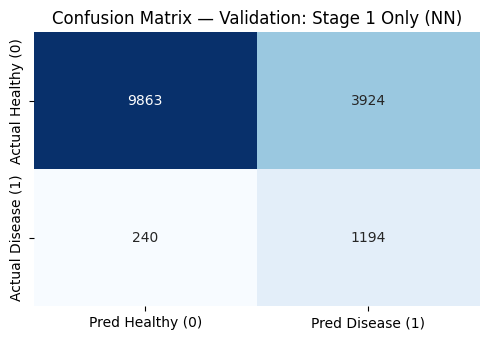

In [28]:
model.eval()
with torch.no_grad():
    val_probs = torch.sigmoid(model(X_val_t)).numpy().flatten()

stage1_val_preds = (val_probs >= 0.45).astype(int)
evaluate_stage(y_val, stage1_val_preds, "Validation: Stage 1 Only (NN)")

## 5. Stage 2: Confidence-Gated Spatial Inspection (One-Class SVM)
To prevent `OneClassSVM` from rejecting severe patients located in the extreme tail of the feature space, we couple Stage 2's spatial distance (`decision_function`) with Stage 1's posterior probability (`prob`):
1. **In-Distribution (`score >= 0.0`):** Confirmed Positive (`1`).
2. **High-Confidence Spatial Outlier (`score < 0.0` and `prob >= conf_thresh`):** Severe or atypical profile; flagged as **Gray Zone / Medical Review (`2`)** while **retaining its Positive (`1`) prediction** to protect Recall.
3. **Low-Confidence Spatial Outlier (`score < 0.0` and `prob < conf_thresh`):** Borderline NN prediction that also fails spatial verification; flipped to **Healthy (`0`)** to eliminate False Positives.

In [29]:
X_train_patients = X_train_scaled[y_train == 1]

ocsvm = OneClassSVM(kernel="rbf", gamma="scale", nu=0.12)
ocsvm.fit(X_train_patients)

OneClassSVM(nu=0.12)

In [30]:
# 0 = Healthy (Stage 1), 1 = Confirmed Positive, 2 = Gray Zone (Protected Positive), -1 = Flipped to Healthy
val_routing_flags = np.zeros_like(stage1_val_preds)
conf_thresh = 0.65  # Stage 1 confidence ceiling above which OCSVM cannot flip to Healthy

pos_indices_val = np.where(stage1_val_preds == 1)[0]
val_spatial_scores = ocsvm.decision_function(X_val_scaled[pos_indices_val])

for idx, score in zip(pos_indices_val, val_spatial_scores):
    if score >= 0.0:
        val_routing_flags[idx] = 1
    elif val_probs[idx] >= conf_thresh:
        val_routing_flags[idx] = 2
    else:
        val_routing_flags[idx] = -1

[Validation] Gray Zone (High-Conf Spatial Outliers — kept Positive): 244
 -> Healthy cases: 161 | True Patients protected: 83

[Validation] Low-Conf Spatial Outliers (Flipped to Healthy): 275
 -> False Positives eliminated: 222 | True Patients lost: 53

=== Validation: Stage 1 + Stage 2 (NN + Confidence-Gated OCSVM) ===
Accuracy : 0.7375
Precision: 0.2356
Recall   : 0.7957
F1-Score : 0.3635

                    Pred Healthy (0)  Pred Disease (1)
Actual Healthy (0)             10085              3702
Actual Disease (1)               293              1141
--------------------------------------------------


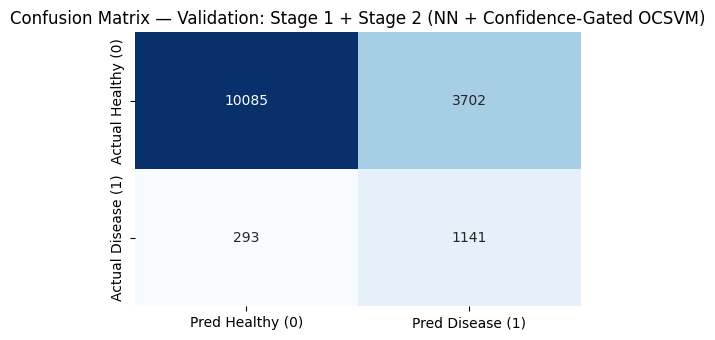

In [31]:
gray_mask_val = (val_routing_flags == 2)
flipped_mask_val = (val_routing_flags == -1)

print(f"[Validation] Gray Zone (High-Conf Spatial Outliers — kept Positive): {gray_mask_val.sum()}")
print(f" -> Healthy cases: {(y_val.values[gray_mask_val] == 0).sum()} | True Patients protected: {(y_val.values[gray_mask_val] == 1).sum()}")

print(f"\n[Validation] Low-Conf Spatial Outliers (Flipped to Healthy): {flipped_mask_val.sum()}")
print(f" -> False Positives eliminated: {(y_val.values[flipped_mask_val] == 0).sum()} | True Patients lost: {(y_val.values[flipped_mask_val] == 1).sum()}\n")

stage2_val_preds = np.where(np.isin(val_routing_flags, [1, 2]), 1, 0)
evaluate_stage(y_val, stage2_val_preds, "Validation: Stage 1 + Stage 2 (NN + Confidence-Gated OCSVM)")

In [32]:
# Create a diagnostic DataFrame using unscaled validation features
diag_df = X_val.copy()

# Add model internal signals (Stage 1 probability & Stage 2 spatial distance)
diag_df["NN_Prob"] = val_probs
diag_df["OCSVM_Score"] = ocsvm.decision_function(X_val_scaled)

# Map each row to its Confusion Matrix category based on Stage 1 predictions
conditions = [
    (y_val == 1) & (stage1_val_preds == 1),
    (y_val == 0) & (stage1_val_preds == 1),
    (y_val == 1) & (stage1_val_preds == 0),
    (y_val == 0) & (stage1_val_preds == 0)
]
choices = ["TP (True Patient)", "FP (False Alarm)", "FN (Missed Patient)", "TN (True Healthy)"]
diag_df["Category"] = np.select(conditions, choices, default="Other")

# Build Pivot Table with Mean and Median for all features across categories
pivot_diag = diag_df.pivot_table(
    index="Category",
    aggfunc=["mean", "median"]
).T

# Swap levels so each feature shows its Mean and Median side-by-side across TP, FP, FN, TN
pivot_diag = pivot_diag.swaplevel(0, 1).sort_index(level=0)
pivot_diag[["TP (True Patient)", "FP (False Alarm)", "FN (Missed Patient)", "TN (True Healthy)"]].round(3)

Category                  TP (True Patient)  FP (False Alarm)  \
Age               mean               10.527            10.143   
                  median             11.000            10.000   
AnyHealthcare     mean                0.967             0.962   
                  median              1.000             1.000   
BMI               mean               29.540            29.628   
                  median             29.000            29.000   
CholCheck         mean                0.990             0.991   
                  median              1.000             1.000   
Diabetes          mean                0.799             0.626   
                  median              0.000             0.000   
DiffWalk          mean                0.487             0.374   
                  median              0.000             0.000   
Education         mean                4.757             4.770   
                  median              5.000             5.000   
Fruits            mean                0.628             0.596   
                  median              1.000             1.000   
GenHlth           mean                3.574             3.245   
                  median              4.000             3.000   
HighBP            mean                0.826             0.749   
                  median              1.000             1.000   
HighChol          mean                0.770             0.694   
                  median              1.000             1.000   
HvyAlcoholConsump mean                0.028             0.037   
                  median              0.000             0.000   
Income            mean                5.010             5.256   
                  median              5.000             6.000   
MentHlth          mean                4.684             4.368   
                  median              0.000             0.000   
NN_Prob           mean                0.717             0.636   
                  median              0.728             0.630   
NoDocbcCost       mean                0.119             0.099   
                  median              0.000             0.000   
OCSVM_Score       mean               12.549            13.240   
                  median             14.241            14.624   
PhysActivity      mean                0.594             0.647   
                  median              1.000             1.000   
PhysHlth          mean               10.281             7.937   
                  median              4.000             1.000   
Sex               mean                0.595             0.567   
                  median              1.000             1.000   
Smoker            mean                0.651             0.607   
                  median              1.000             1.000   
Stroke            mean                0.199             0.089   
                  median              0.000             0.000   
Veggies           mean                0.760             0.770   
                  median              1.000             1.000   

Category                  FN (Missed Patient)  TN (True Healthy)  
Age               mean                  8.621              6.974  
                  median                9.000              7.000  
AnyHealthcare     mean                  0.938              0.947  
                  median                1.000              1.000  
BMI               mean                 28.425             27.642  
                  median               27.500             27.000  
CholCheck         mean                  0.958              0.948  
                  median                1.000              1.000  
Diabetes          mean                  0.188              0.112  
                  median                0.000              0.000  
DiffWalk          mean                  0.142              0.056  
                  median                0.000              0.000  
Education         mean                  4.954              5.194  
      

## 6. Final Benchmark on Unseen Test Set
We apply the exact same confidence-gated two-stage pipeline to the isolated `Test Set`.

=== Test Set: Stage 1 Only (NN) ===
Accuracy : 0.7574
Precision: 0.2492
Recall   : 0.7837
F1-Score : 0.3782

                    Pred Healthy (0)  Pred Disease (1)
Actual Healthy (0)             10405              3383
Actual Disease (1)               310              1123
--------------------------------------------------


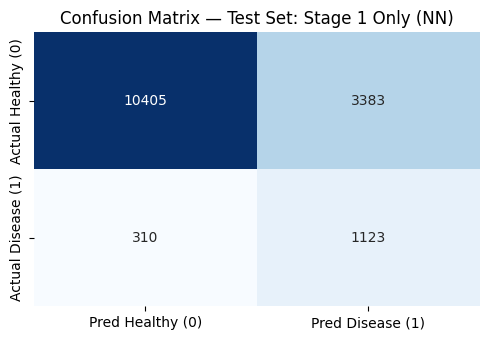

In [33]:
model.eval()
with torch.no_grad():
    test_probs = torch.sigmoid(model(X_test_t)).numpy().flatten()

stage1_test_preds = (test_probs >= 0.50).astype(int)
evaluate_stage(y_test, stage1_test_preds, "Test Set: Stage 1 Only (NN)")

[Test Set] Gray Zone (High-Conf Spatial Outliers — kept Positive): 262
 -> Healthy cases: 174 | True Patients protected: 88

[Test Set] Low-Conf Spatial Outliers (Flipped to Healthy): 245
 -> False Positives eliminated: 198 | True Patients lost: 47

=== Test Set: Stage 1 + Stage 2 (NN + Confidence-Gated OCSVM) ===
Accuracy : 0.7673
Precision: 0.2525
Recall   : 0.7509
F1-Score : 0.3779

                    Pred Healthy (0)  Pred Disease (1)
Actual Healthy (0)             10603              3185
Actual Disease (1)               357              1076
--------------------------------------------------


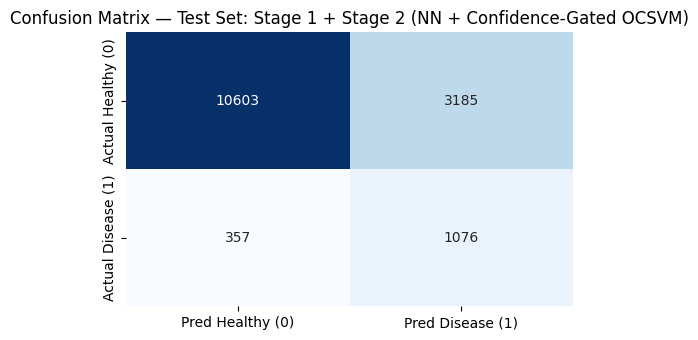

In [34]:
test_routing_flags = np.zeros_like(stage1_test_preds)
pos_indices_test = np.where(stage1_test_preds == 1)[0]
test_spatial_scores = ocsvm.decision_function(X_test_scaled[pos_indices_test])

for idx, score in zip(pos_indices_test, test_spatial_scores):
    if score >= 0.0:
        test_routing_flags[idx] = 1
    elif test_probs[idx] >= conf_thresh:
        test_routing_flags[idx] = 2
    else:
        test_routing_flags[idx] = -1

gray_mask_test = (test_routing_flags == 2)
flipped_mask_test = (test_routing_flags == -1)

print(f"[Test Set] Gray Zone (High-Conf Spatial Outliers — kept Positive): {gray_mask_test.sum()}")
print(f" -> Healthy cases: {(y_test.values[gray_mask_test] == 0).sum()} | True Patients protected: {(y_test.values[gray_mask_test] == 1).sum()}")

print(f"\n[Test Set] Low-Conf Spatial Outliers (Flipped to Healthy): {flipped_mask_test.sum()}")
print(f" -> False Positives eliminated: {(y_test.values[flipped_mask_test] == 0).sum()} | True Patients lost: {(y_test.values[flipped_mask_test] == 1).sum()}\n")

stage2_test_preds = np.where(np.isin(test_routing_flags, [1, 2]), 1, 0)
evaluate_stage(y_test, stage2_test_preds, "Test Set: Stage 1 + Stage 2 (NN + Confidence-Gated OCSVM)")

## 7. Conclusion & Future Work

**1. The Data Information Limit (Bayes Error Rate):**  EDA and diagnostic pivot tables revealed a severe spatial overlap between False Positives (FP) and True Positives (TP), as well as between False Negatives (FN) and True Negatives (TN). These overlapping groups share nearly identical behavioral profiles in this dataset (e.g., similar Age, HighBP, BMI, and GenHlth metrics). Because this data is based on general surveys rather than clinical measurements (e.g., ECG, Troponin levels), it inherently lacks the discriminative features required to perfectly isolate true patients.

**2. Future Directions:** To break through this data overlap in future iterations, we can explore:
* **Advanced Loss Functions:** Implementing `Focal Loss` instead of standard BCE to force the neural network to dynamically penalize hard, overlapping examples during gradient descent.
* **Feature Engineering:** Creating composite risk indicators (e.g., a "Metabolic Syndrome Flag") to construct new dimensions for linear separability.